# Load Data

In [7]:
import pandas as pd

df = pd.read_csv('dataset_shopee_playstore.csv')
df.head()

,review,rating,sentimen
0,sekarang shopee tambah bagus saya sering beli ...,5,positif
1,Sangat membantu dalam bisnis maupun kebutuhan,5,positif
2,seminggu gada update paketnya nyangkut untuk p...,2,negatif
3,praktis,5,positif
4,"ap kah penjualan di shopee tidak ad penipuan,,...",5,positif


# Preprocessing

In [ ]:
!pip install Sastrawi

In [ ]:
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def clean_text(text):
  text = text.lower()
  text = re.sub(r'[^a-zA-Z ]', '', text)
  text = stemmer.stem(text)
  return text

df['clean_review'] = df['review'].apply(clean_text)

# TF-IDF



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df['clean_review'])
y = df['sentimen']

# Split Data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model

Model 1 : SVM

In [ ]:
from sklearn.svm import SVC

model_svm = SVC()
model_svm.fit(X_train, y_train)

print("SVM Accuracy:", model_svm.score(X_test, y_test))

SVM Accuracy: 0.882


Model 2 : Naive Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB

model_nb = MultinomialNB()
model_nb.fit(X_train, y_train)

print("NB Accuracy:", model_nb.score(X_test, y_test))

NB Accuracy: 0.8725


Model 3 : Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier()
model_rf.fit(X_train, y_train)

print("RF Accuracy:", model_rf.score(X_test, y_test))

RF Accuracy: 0.8675


# Gridsearch

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf']
}

grid = GridSearchCV(SVC(), param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best score:", grid.best_score_)

Best params: {'C': 1, 'kernel': 'rbf'}
Best score: 0.8806245899682644


# Evaluasi + Confusion Matrix

              precision    recall  f1-score   support

     negatif       0.78      0.80      0.79       500
      netral       0.00      0.00      0.00        63
     positif       0.92      0.95      0.93      1437

    accuracy                           0.88      2000
   macro avg       0.57      0.58      0.57      2000
weighted avg       0.85      0.88      0.87      2000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


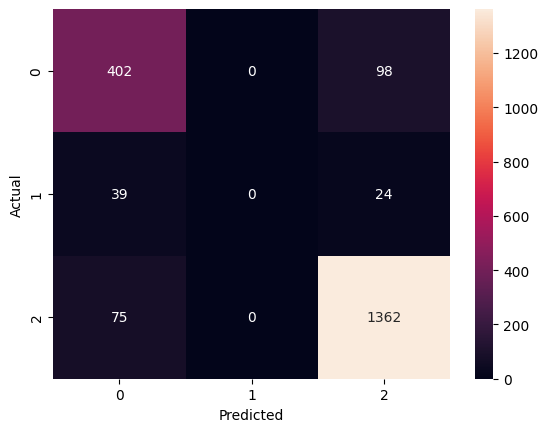

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model_svm.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Wordcloud

# Inference

In [ ]:
text = ["aplikasinya bagus banget"]

clean = clean_text(text[0])
vector = tfidf.transform([clean])

pred = model_svm.predict(vector)
print("Hasil prediksi:", pred)

Hasil prediksi: ['positif']


# Simpan

In [6]:
df.to_csv('dataset_shopee_playstore.csv', index=False)